# KQC DaisyWoven — flip-chip indium-bump daisy-chain test chip (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/daisy_woven.py` (class `DaisyWoven`, chip name "DC"; © IQM Finland Oy,
GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/daisy_woven.py`; the pattern is KQC's static cell
`elements/daisy_woven.oas`; spec `docs/designs/kqc/daisy_woven.md`). A process test for flip-chip bonding: the same
hand-drawn daisy-chain pattern on both faces (bottom chip `1t1`, top chip `2b1`) — Nb wiring, under-bump
metallization (UBM) and indium bumps — with probe pads around the edge and the number of bumps per chain written
next to each pad pair (2, 40, 80, 200, 2080). It is measured by DC resistance after bonding; there are no qubits,
resonators or RF lines.

This notebook **rebuilds** the chip on the Quantcore PDK — not a replica. We distribute the rebuild under
GPL-3.0. Most steps of a circuit notebook (launchers, routes, LOM, FEM, iterate) have nothing to act on here; each
says so.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` on both faces | same 10 × 10 mm; the KQC chip cell is placed with `frames_enabled=[]`, so the Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "DC") replaces KQC's frame; the top chip gets no frame (PDK v3 defines none for it; its layers export to 800–804/0) |
| pattern | `DaisyWoven.build()`: the static pattern inverted over the chip box, UBM and indium bumps | the same KQC cell, so its own `build()` runs unchanged |
| pads | probe pads drawn in the static pattern | kept where the pattern has them (they are part of one static drawing, not pad instances; see Design 3) |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 (it changes nothing here: there is no circuit to simulate) |
| junctions | none | none |
| cheese | none: `DaisyWoven` puts the whole chip box into `ground_grid_avoidance`, and the metal is only the pattern | **the original wins:** chip `cheese: "original"` — no PDK band |
| placement | the pattern fills the chip | the same (centred by construction) |

**Kept exactly:** the whole chip is the KQC `DaisyWoven` PCell placed once at the chip origin, so its `build()` runs
unchanged: the polarity inversion of the static pattern (chip box − pattern − existing avoidance →
`base_metal_gap_wo_grid`), the UBM (802/0 in the mask) and the indium bumps (801/0).

**Simplified / substituted:** nothing. Placing the KQC chip class as one cell imports the static pattern the KQC way.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the empty die, the KQC chip cell placed (and the design saved), then views of its parts: the probe pads against the pad rule, and the daisy chains with their indium bumps. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `daisy_woven.v1.ipynb`; both save the same `daisy_woven.json`.

This chip is one KQC PCell with a static pattern and no circuit: the LOM, Simulate and Results steps say in one sentence each why they do not apply; Check and Fab run as in the v1.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/daisy_woven/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")                            # design JSON + final snapshots
STEPS = Path("build/snapshots/daisy_woven")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip uses the frame, the flip-chip layers (800–804/0) and the fab layer map; it has no junctions, no
CPWs and no cheese.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The whole chip is one KQC PCell, `DaisyWoven`: its static pattern draws the probe pads, the daisy chains and the
bump-count labels in one piece, and its `build()` adds the UBM and the indium bumps on both faces. The layout cannot
be split into segments without redrawing that pattern (a redesign, not a rebuild), so the segments are the empty die,
the cell placed (and the design saved there, as in the v1), and then views of its parts with the numbers that make
them. Each view is a zoom of the same build (no rebuild).

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame (device ID DC), no cheese (`cheese: "original"`) |
| 2 | the whole chip: KQC's `DaisyWoven` cell at the origin, with KQC's frames off; the save |
| 3 | a view: the probe pads of the static pattern, measured against the pad rule |
| 4 | a view: the daisy chains and the indium bumps, counted per face |

## Design 1 · The empty die and its frame

`Designer(...)` starts the 10 × 10 mm chip with the name "DC" (the device ID). The chip cheese is `"original"`: the
source has none (its build puts the whole chip box into KQC's `ground_grid_avoidance`), so no PDK band is drawn.

The picture is the die with nothing on it but the Quantcore frame.

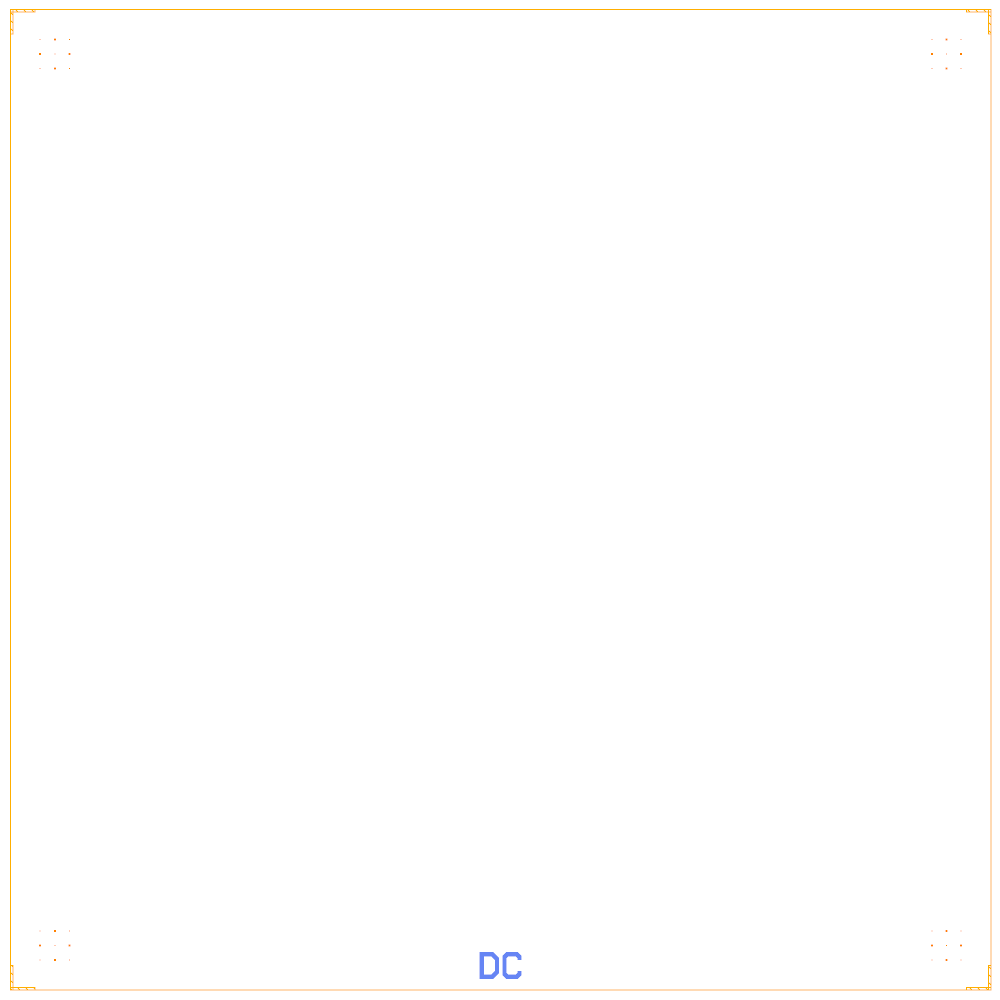

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/daisy_woven/s1_die.png')

In [5]:
d = Designer("daisy_woven", box=(0, 0, 10000, 10000), chip={"name_chip": "DC", "cheese": "original"}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "s1_die.png", **CHIP)

## Design 2 · The chip cell: `DaisyWoven`, placed once

The whole design is one instance: KQC's `DaisyWoven` chip PCell at the chip origin with `frames_enabled=[]`, so KQC
draws no `ChipFrame` on either face and the Designer chip draws the Quantcore die frame (L dicing markers on 1000/0,
3 × 3 alignment grids on 1001/0, the chip boundary on 100/0). Then the design is saved: `daisy_woven.json` is what
DRC, the fab export and `qcc` read. `save_design` compares it with the file it replaces (the previous run's):
it should say *same design*.

The table lists the cell's own parameters (KQC `get_schema`) and this design's values: `frames_enabled=[]` is the
only one set (KQC's frames off, the Quantcore frame instead); everything else the cell draws comes from its static
pattern file.

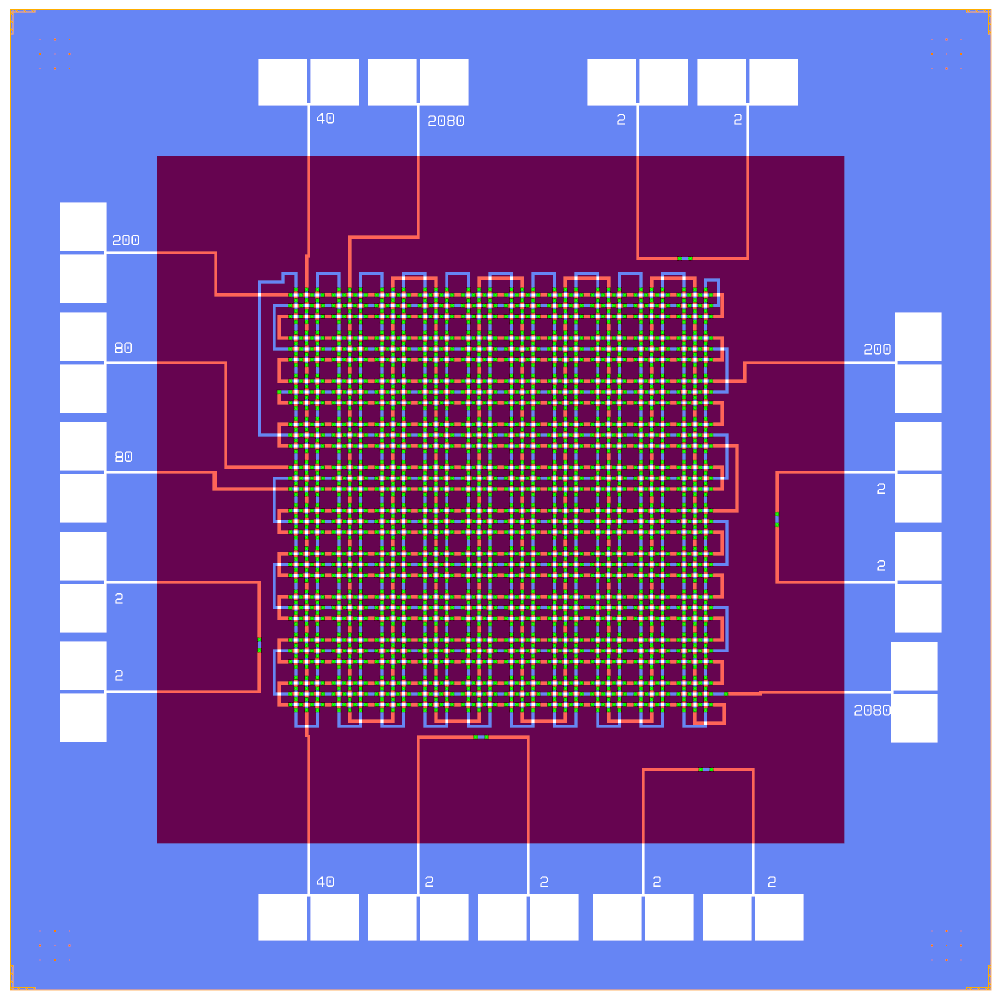

**On the chip so far:** 0 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `DC`.

**Same design as before:** `examples/designs/kqc/daisy_woven.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer daisy_woven: 1 instances, 0 routes, live=False> → examples\designs\kqc\daisy_woven.json


**`DaisyWoven`** parameters:

| parameter | default | this design | meaning |
|---|---|---|---|
| `name_chip` | DC | (default) | Name of the chip |
| `frames_enabled` | [0, 1] | [] | List of face ids (integers) for which a ChipFrame is drawn |

In [6]:
d.add("DC", "DaisyWoven", at=(0, 0), frames_enabled=[])   # KQC chip PCell: static daisy pattern, UBM, indium bumps
layout_step(d, STEPS / "1_die.png", **CHIP)
DESIGN, same = save_design(d, OUT / "daisy_woven.json")
display(Markdown(same))
print(d, "→", DESIGN)
display(Markdown(pcell_params_md("DaisyWoven", d.data["instances"]["DC"]["params"])))

## Design 3 · A view: the probe pads and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"` on a pad instance). This chip has no pad instances: its probe pads are part of KQC's static
pattern, one drawing with the chains and the bump counts, so the rule cannot move them without redrawing the
pattern, and the DRC's `pad_edge` check does not see them. The cell below measures where the pattern's metal
ends: the metal is what the inversion leaves unetched on the bottom face.

The picture zooms on two of the north pad pairs with their bump-count labels (40 and 2080 bumps).

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

bottom-face metal spans (500, 500) – (9499, 9500) µm: 500 µm from the nearest die edge


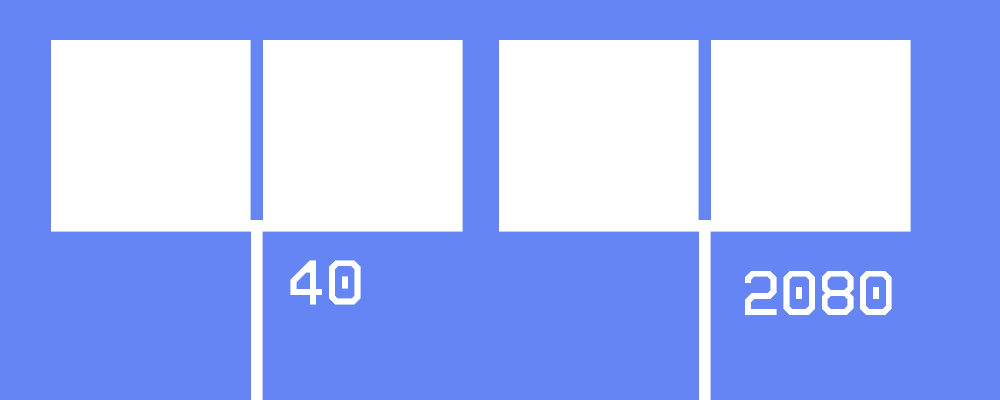

In [7]:
display(Markdown(pads_md(d)))
import klayout.db as kdb
rebuild(d)
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()


def layer_region(name):
    li = next((i for i in ly.layer_indexes() if ly.get_info(i).name == name), None)
    return kdb.Region() if li is None else kdb.Region(top.begin_shapes_rec(li)).merged()


x0, y0, x1, y1 = d.design.chip.box
die = kdb.Region(kdb.DBox(x0, y0, x1, y1).to_itype(ly.dbu))
metal = die - layer_region("1t1_base_metal_gap_wo_grid")   # what the inversion leaves unetched (bottom face)
mb = metal.bbox().to_dtype(ly.dbu)
print(f"bottom-face metal spans ({mb.left:.0f}, {mb.bottom:.0f}) – ({mb.right:.0f}, {mb.top:.0f}) µm: "
      f"{min(mb.left - x0, mb.bottom - y0, x1 - mb.right, y1 - mb.top):.0f} µm from the nearest die edge")
snap(d, STEPS / "s3_pads.png", box=(2400, 8600, 4900, 9600), size=(1000, 400), width=500);

**From the v1 run:** no pad instances. The bottom-face metal (chains and probe pads) spans (500, 500) – (9500, 9500) µm: the static pattern keeps a 500 µm border, so its outer probe pads end 500 µm from the die edge, 400 µm further in than the rule's 100 µm. They are left there (moving them means redrawing the pattern); the DRC raises no `pad_edge` warning because they are not pad instances.

## Design 4 · A view: the daisy chains and the indium bumps

What this chip measures is the resistance of each bump chain after bonding, so the useful numbers are the bump and
UBM counts per face, from the built layout (one indium bump on each UBM pad; the two faces carry the same pattern, so
the bumps meet when the top chip is flipped on). The picture shows the chain array (bottom face blue, top face red).
There are no routes: the chains are drawn in the static pattern.

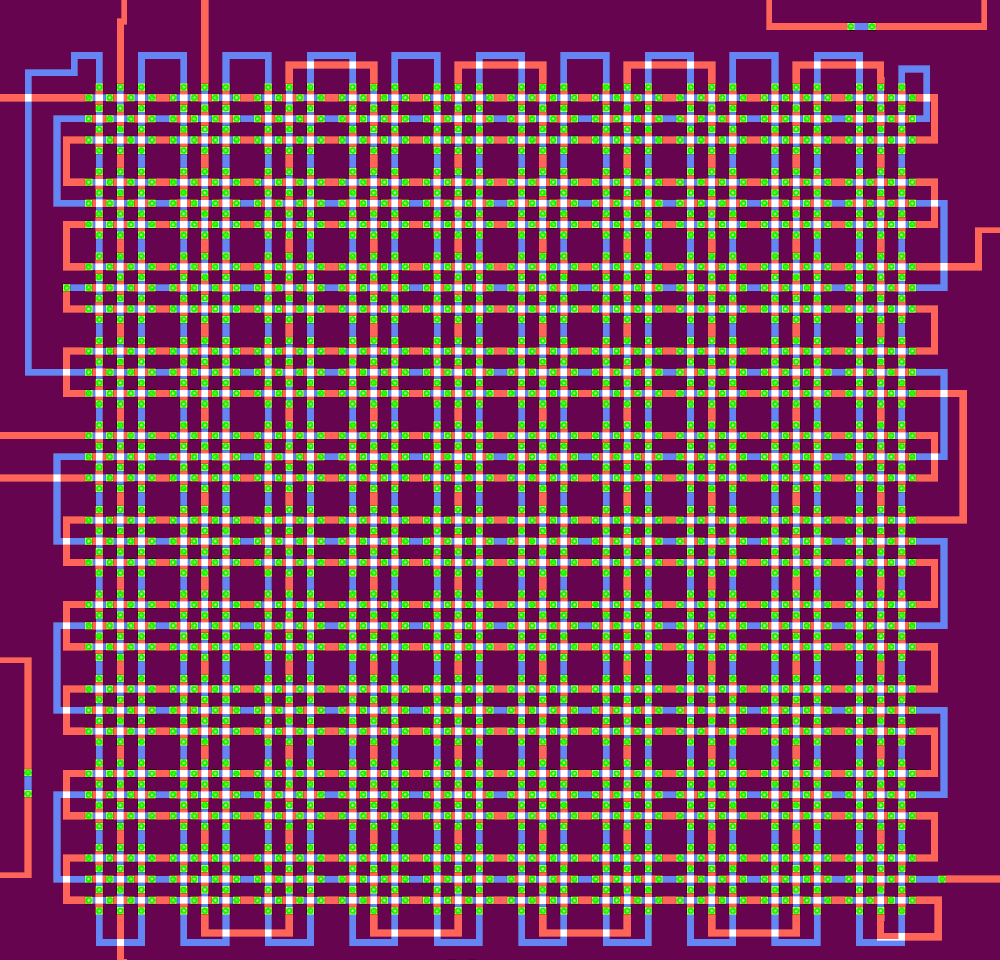

| face | indium bumps | UBM pads | bump size (µm) | etched area (mm²) |
|---|---|---|---|---|
| 1t1 | 2412 | 2412 | 24 × 24 | 82.31 |
| 2b1 | 2412 | 2412 | 24 × 24 | 41.10 |

In [8]:
snap(d, STEPS / "s4_chains.png", box=(2400, 2600, 7600, 7600), size=(1000, 960), width=480);
rows = ["| face | indium bumps | UBM pads | bump size (µm) | etched area (mm²) |", "|---|---|---|---|---|"]
for face in ("1t1", "2b1"):
    bumps, ubm = layer_region(f"{face}_indium_bump"), layer_region(f"{face}_underbump_metallization")
    gap = layer_region(f"{face}_base_metal_gap_wo_grid")
    b0 = next(iter(bumps.each())).bbox() if bumps.count() else None
    size = f"{b0.width() * ly.dbu:.0f} × {b0.height() * ly.dbu:.0f}" if b0 else "–"
    rows.append(f"| {face} | {bumps.count()} | {ubm.count()} | {size} | {gap.area() * ly.dbu ** 2 / 1e6:.2f} |")
display(Markdown("\n".join(rows)))

**From the v1 run:** 2412 indium bumps on 2412 UBM pads per face, 24 × 24 µm each. The base etch covers 82.31 mm² of the bottom chip and 41.10 mm² of the top chip (the top chip is the inner ≈ 7 × 7 mm).

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** 0 errors and 9 warnings, all from the frame: `frame_keepout` × 8 (the `DC` cell overlaps the corner marker areas) and `frame_margin` × 1 (it reaches into the 100 µm die margin). They are real: `DaisyWoven` inverts its pattern over the whole chip box, so the base etch 1/0 also covers the die corners under the PDK markers (1000/0 and 1001/0 are their own fab layers; the frame-corner snapshot shows it). A fab version would stop the inversion at the design area. No PDK design warning; `pdk_report` gives no cheese ("the original design's own (or none)"), the content centred (0, 0) and no junctions.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models. No component here has one (the
daisy chains are DC test structures), so the netlist is ground only.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: nothing to simulate

The netlist is ground only (Check 2): the daisy chains are DC test structures with no LOM model, so there are no
modes; the chip's numbers are the bump counts of Design 4.

# Simulate: nothing to export

The design has no sim groups (a DC daisy chain has nothing for a C-matrix, eigenmode or driven solve), so the export
below writes no FEM job, and the switches at the top change nothing here.

In [ ]:
jobs = export_sims(DESIGN)                       # one job per sim group: this design has none
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Results: no feedback loop

There is no simulated quantity and no target: `DaisyWoven` has no parameters of its own beyond the KQC `Chip` ones
(the pattern is a static file), so a variant is a new static pattern, not a knob to iterate. The comparison this chip
has is the XOR against KQC's own build (Fab 2).

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `daisy_woven.json` (saved in Design 2) is the whole design: `qcc build
examples/designs/kqc/daisy_woven.json` rebuilds `build/daisy_woven.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers (there are none),
and the frame (100/0, 1000/0, 1001/0). The cheese source is `original` with no holes: the source has no cheese, and none is added. The
top chip's etch (face 2b1) goes to 800/0; the indium bumps and the UBM of both faces go to 801/0 and
802/0 (the PDK collects both faces there; the two patterns coincide). In the v1 run: 1/0 23 polygons, 3/0 1 (the keep-out covers the whole etched area), 800/0 1, 801/0 and 802/0 2412 each, 100/0 1, 1000/0 4, 1001/0 36; cheese source `original`, 0 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/daisy_woven.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip (bottom face blue, top face red); a zoom on the bump array and one daisy-chain corner; the die frame's
south-west corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); the bump array in the **fab view** (the mask
from Fab 1). The chip boundary 100/0 is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "daisy_woven.png")
show_snapshot(d, OUT / "daisy_woven_bumps.png", box=(4700, 4700, 5300, 5300), width=420)
show_snapshot(d, OUT / "daisy_woven_corner.png", box=(2400, 6800, 3200, 7600), width=420)
show_snapshot(d, OUT / "daisy_woven_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "daisy_woven_fab.oas", OUT / "daisy_woven_fab_bumps.png", box=(4800, 4800, 5200, 5200),
          size=(1200, 1200), width=420);   # fab view

**Reference: XOR with the source.** KQC's `DaisyWoven` built stand-alone (with KQC's own frames), XOR-ed layer by
layer with this build (`refpoints` skipped). **The rebuild is expected to differ** by design in the frame (KQC's
ChipFrame on both faces vs the Quantcore die frame on the bottom chip); the pattern, UBM and bump layers should
agree. A reference, not a pass/fail check.

In [ ]:
from kqcircuits.chips.daisy_woven import DaisyWoven
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(DaisyWoven.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "daisy_woven_kqc_original.oas"))
xor_rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(ref_top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints",):
        continue
    b = layer_region(info.name)
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    xor_rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(xor_rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "daisy_woven_kqc_original.oas", OUT / "daisy_woven_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

**From the v1 run:** the UBM and indium-bump layers agree exactly (XOR 0) on both faces. The base etch differs by 6.14 mm² (bottom) and 4.54 mm² (top), and KQC's build has EBL, airbridge-pad and dicing-edge shapes this one lacks: KQC's frames (dicing edge, corner markers and chip labels, with their avoidance areas, which the inversion leaves unetched) are not drawn here.

## Summary

| | |
|---|---|
| **matches the source** | the whole `DaisyWoven` cell (KQC's own `build()`): the inverted static pattern, UBM and indium bumps on both faces; no cheese, as in the source |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame (bottom chip; none on the top chip); the PDK fab layer map (1/0, 800–802/0, 1000/0, 1001/0, 100/0) |
| **not applicable** | launchers and the pad rule (the probe pads are in the static pattern), routes, LOM, FEM, the iterate step |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | no sim groups, no jobs |
| layout | the empty die, the chip cell placed (one KQC PCell, saved there), then two views of its parts (the probe pads, the chains and bumps); the saved JSON is the v1 notebook's |
| feedback | none: no parameters of its own and no simulated quantity |
| open | the base etch reaches the die corners under the PDK markers (DRC `frame_keepout`, `frame_margin`): a fab version stops the inversion at the design area |